In [1]:
# install pqdm for parallel processing
!pip install --no-index --find-links=/kaggle/input/ariel-2024-pqdm pqdm

Looking in links: /kaggle/input/ariel-2024-pqdm
Processing /kaggle/input/ariel-2024-pqdm/pqdm-0.2.0-py2.py3-none-any.whl
Processing /kaggle/input/ariel-2024-pqdm/bounded_pool_executor-0.0.3-py3-none-any.whl (from pqdm)


In [2]:
import pandas as pd
import numpy as np
import pandas.api.types
import scipy.stats

from tqdm import tqdm
from pqdm.threads import pqdm
import itertools
import pickle

from scipy.optimize import minimize
from sklearn.metrics import mean_squared_error

import plotly.express as px

from astropy.stats import sigma_clip
from scipy.signal import savgol_filter

In [3]:
class Config:
    DATA_PATH = '/kaggle/input/ariel-data-challenge-2025'
    DATASET = "test"

    SCALE = 0.927
    SIGMA = 0.0009
    
    CUT_INF = 39
    CUT_SUP = 250
    
    SENSOR_CONFIG = {
        "AIRS-CH0": {
            "raw_shape": [11250, 32, 356],
            "calibrated_shape": [1, 32, CUT_SUP - CUT_INF],
            "linear_corr_shape": (6, 32, 356),
            "dt_pattern": (0.1, 4.5), 
            "binning": 30
        },
        "FGS1": {
            "raw_shape": [135000, 32, 32],
            "calibrated_shape": [1, 32, 32],
            "linear_corr_shape": (6, 32, 32),
            "dt_pattern": (0.1, 0.1),
            "binning": 30 * 12
        }
    }
    
    MODEL_PHASE_DETECTION_SLICE = slice(0, 186)
    MODEL_OPTIMIZATION_DELTA = 7
    MODEL_POLYNOMIAL_DEGREE = 3
    
    N_JOBS = 4

In [4]:
class SignalProcessor:
    def __init__(self, config):
        self.cfg = config
        self.adc_info = pd.read_csv(f"{self.cfg.DATA_PATH}/adc_info.csv")
        self.planet_ids = pd.read_csv(f'{self.cfg.DATA_PATH}/{self.cfg.DATASET}_star_info.csv', index_col='planet_id').index.astype(int)

    def _apply_linear_corr(self, linear_corr, signal):
        linear_corr_flipped = np.flip(linear_corr, axis=0)
        corrected_signal = signal.copy()
        
        for x, y in itertools.product(range(signal.shape[1]), range(signal.shape[2])):
            poly = np.poly1d(linear_corr_flipped[:, x, y])
            corrected_signal[:, x, y] = poly(corrected_signal[:, x, y])
            
        return corrected_signal

    def _calibrate_single_signal(self, planet_id, sensor):
        sensor_cfg = self.cfg.SENSOR_CONFIG[sensor]

        signal = pd.read_parquet(f"{self.cfg.DATA_PATH}/{self.cfg.DATASET}/{planet_id}/{sensor}_signal_0.parquet").to_numpy()
        dark = pd.read_parquet(f"{self.cfg.DATA_PATH}/{self.cfg.DATASET}/{planet_id}/{sensor}_calibration_0/dark.parquet").to_numpy()
        dead = pd.read_parquet(f"{self.cfg.DATA_PATH}/{self.cfg.DATASET}/{planet_id}/{sensor}_calibration_0/dead.parquet").to_numpy()
        flat = pd.read_parquet(f"{self.cfg.DATA_PATH}/{self.cfg.DATASET}/{planet_id}/{sensor}_calibration_0/flat.parquet").to_numpy()
        linear_corr = pd.read_parquet(f"{self.cfg.DATA_PATH}/{self.cfg.DATASET}/{planet_id}/{sensor}_calibration_0/linear_corr.parquet").values.astype(np.float64).reshape(sensor_cfg["linear_corr_shape"])

        signal = signal.reshape(sensor_cfg["raw_shape"])
        gain = self.adc_info[f"{sensor}_adc_gain"].iloc[0]
        offset = self.adc_info[f"{sensor}_adc_offset"].iloc[0]
        signal = signal / gain + offset

        hot = sigma_clip(dark, sigma=5, maxiters=5).mask

        if sensor == "AIRS-CH0":
            signal = signal[:, :, self.cfg.CUT_INF : self.cfg.CUT_SUP]
            linear_corr = linear_corr[:, :, self.cfg.CUT_INF : self.cfg.CUT_SUP]
            dark = dark[:, self.cfg.CUT_INF : self.cfg.CUT_SUP]
            dead = dead[:, self.cfg.CUT_INF : self.cfg.CUT_SUP]
            flat = flat[:, self.cfg.CUT_INF : self.cfg.CUT_SUP]
            hot = hot[:, self.cfg.CUT_INF : self.cfg.CUT_SUP]
        
        base_dt, increment = sensor_cfg["dt_pattern"]
        dt = np.ones(len(signal)) * base_dt
        dt[1::2] += increment
        
        signal = signal.clip(0)
        signal = self._apply_linear_corr(linear_corr, signal)
        signal -= dark * dt[:, np.newaxis, np.newaxis]
        
        flat = flat.reshape(sensor_cfg["calibrated_shape"])
        flat[dead.reshape(sensor_cfg["calibrated_shape"])] = np.nan
        flat[hot.reshape(sensor_cfg["calibrated_shape"])] = np.nan
        
        signal = signal / flat
        
        return signal

    def _preprocess_calibrated_signal(self, calibrated_signal, sensor):
        sensor_cfg = self.cfg.SENSOR_CONFIG[sensor]
        binning = sensor_cfg["binning"]

        if sensor == "AIRS-CH0":
            signal_roi = calibrated_signal[:, 10:22, :]
        elif sensor == "FGS1":
            signal_roi = calibrated_signal[:, 10:22, 10:22]
            signal_roi = signal_roi.reshape(signal_roi.shape[0], -1)
        
        mean_signal = np.nanmean(signal_roi, axis=1)

        cds_signal = mean_signal[1::2] - mean_signal[0::2]

        n_bins = cds_signal.shape[0] // binning
        binned = np.array([
            cds_signal[j*binning : (j+1)*binning].mean(axis=0) 
            for j in range(n_bins)
        ])

        if sensor == "FGS1":
            binned = binned.reshape((binned.shape[0], 1))
            
        return binned

    def _process_planet_sensor(self, args):
        planet_id, sensor = args['planet_id'], args['sensor']
        calibrated = self._calibrate_single_signal(planet_id, sensor)
        preprocessed = self._preprocess_calibrated_signal(calibrated, sensor)
        return preprocessed

    def process_all_data(self):
        args_fgs1 = [dict(planet_id=planet_id, sensor="FGS1") for planet_id in self.planet_ids]
        preprocessed_fgs1 = pqdm(args_fgs1, self._process_planet_sensor, n_jobs=self.cfg.N_JOBS)

        args_airs_ch0 = [dict(planet_id=planet_id, sensor="AIRS-CH0") for planet_id in self.planet_ids]
        preprocessed_airs_ch0 = pqdm(args_airs_ch0, self._process_planet_sensor, n_jobs=self.cfg.N_JOBS)

        preprocessed_signal = np.concatenate(
            [np.stack(preprocessed_fgs1), np.stack(preprocessed_airs_ch0)], axis=2
        )
        return preprocessed_signal

In [5]:
class TransitModel:
    def __init__(self, config):
        self.cfg = config

    def _phase_detector(self, signal):
        search_slice = self.cfg.MODEL_PHASE_DETECTION_SLICE
        min_index = np.argmin(signal[search_slice]) + search_slice.start
    
        signal1 = signal[:min_index]
        signal2 = signal[min_index:]
    
        grad1 = np.abs(np.gradient(signal1))
        phase1 = np.argmax(grad1)
    
        grad2 = np.abs(np.gradient(signal2))
        phase2 = np.argmax(grad2) + min_index
    
        return phase1, phase2
    
    def _objective_function(self, s, signal, phase1, phase2, middle):
        delta = self.cfg.MODEL_OPTIMIZATION_DELTA
        power = self.cfg.MODEL_POLYNOMIAL_DEGREE
        off=7

        middle_point = (np.floor((phase2-phase1)/2)+phase1).astype(int)
        half_size = (np.floor(middle*(phase2-phase1)/2)).astype(int)
        #print(phase1, middle_point-half_size, middle_point, middle_point+half_size, phase2)


        begin = phase1-off
        end = phase2+off
        '''
        # Handle edge cases
        if begin < 1:
            begin = 1
            begin_pad = np.repeat(signal[0], 20)
        else:
            begin_pad = np.array([])
        
        if end > 186:
            end = 186
            end_pad = np.repeat(signal[186], 20)
        else:
            end_pad = np.array([])
        
        # Construct y
        y = np.concatenate([
            begin_pad,
            signal[:begin],
            signal[middle_point - half_size : middle_point + half_size] * (1 + s),
            signal[end:],
            end_pad
        ])
        '''
        
      
        if begin<1:
            begin=1
        if end>186:
            end=186
        # Construct y
        y = np.concatenate([
            signal[:begin],
            signal[middle_point - half_size : middle_point + half_size] * (1 + s),
            signal[end:]
        ])

        
        x = np.arange(len(y))

        coeffs = np.polyfit(x, y, deg=power)
        poly = np.poly1d(coeffs)
        error = np.abs(poly(x) - y).mean()
        
        return error

    def predict(self, single_preprocessed_signal, middle):
        # Step 1: Reduce to 1D signal
        signal_1d = single_preprocessed_signal[:, :].mean(axis=1)
    
        # Step 2: Denoise for detection and fitting
        signal_1d_detection = savgol_filter(signal_1d, 31, 2)
        signal_1d = savgol_filter(signal_1d, 11, 3)
    
        # Step 3: Detect phases
        phase1, phase2 = self._phase_detector(signal_1d_detection)
        
        
        # Step 4: Check for edge/cut-off cases
        if phase1 < 15 or phase2 > 174:
            # Fallback to min-max depth estimation
            depth_estimate = (signal_1d.max() - signal_1d.min())/(signal_1d.max())
            return depth_estimate
        
        # Step 5: Clamp for optimization bounds
        phase1 = max(self.cfg.MODEL_OPTIMIZATION_DELTA, phase1)
        phase2 = min(len(signal_1d) - self.cfg.MODEL_OPTIMIZATION_DELTA - 1, phase2)
    
        # Step 6: Optimize
        result = minimize(
            fun=self._objective_function,
            x0=[0.0001],
            args=(signal_1d, phase1, phase2, middle),
            method="Nelder-Mead"
        )
       
        
        return result.x[0]


    def predict_all(self, preprocessed_signals, middle):
        predictions = [
            self.predict(preprocessed_signal, middle)
            for preprocessed_signal in tqdm(preprocessed_signals)
        ]
        return np.array(predictions) * self.cfg.SCALE

In [6]:
class SubmissionGenerator:
    def __init__(self, config):
        self.cfg = config
        self.sample_submission = pd.read_csv(f"{self.cfg.DATA_PATH}/sample_submission.csv", index_col="planet_id")
        

    def create(self, predictions):
        planet_ids = self.sample_submission.index
        repeated_predictions = np.repeat(predictions, self.sample_submission.shape[1] // 2).reshape(len(predictions), -1)
        repeated_predictions = repeated_predictions.clip(0)
        
        sigmas = np.ones_like(repeated_predictions) * self.cfg.SIGMA

        submission_df = pd.DataFrame(
            np.concatenate([repeated_predictions, sigmas], axis=1),
            columns=self.sample_submission.columns,
            index=planet_ids
        )
        
        submission_df.to_csv("submission.csv")
        return submission_df

In [7]:
config = Config()
model = TransitModel(config)

signal_processor = SignalProcessor(config)
#preprocessed_data = signal_processor.process_all_data()

preprocessed_data = np.load("/kaggle/input/900preprocessed-planets/preprocessed_data.npy")

model = TransitModel(config)
predictions = model.predict_all(preprocessed_data, 0.45)

#submission_generator = SubmissionGenerator(config)
#submission = submission_generator.create(predictions)

#submission

100%|██████████| 900/900 [00:11<00:00, 75.52it/s]


In [8]:
train = pd.read_csv("/kaggle/input/ariel-data-challenge-2025/train.csv")
train_avg = np.mean(train.iloc[:900, 1:].values, axis=1, keepdims=False)
print(predictions.shape)
print(train_avg.shape)
print(predictions[:5])
print(train_avg[:5])

(900,)
(900,)
[0.01841022 0.00625957 0.04816229 0.0147254  0.01487372]
[0.01813116 0.00633992 0.0462723  0.01549183 0.01463472]


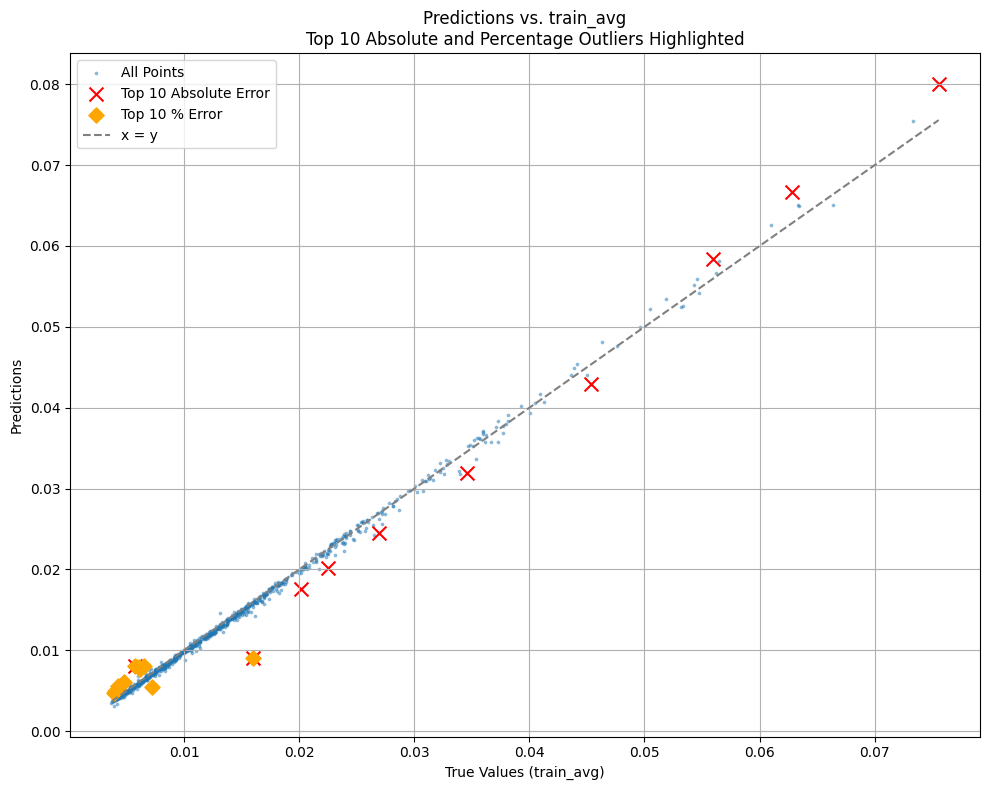

Top 10 Outliers by Absolute Error:
Index | Actual | Predicted | Absolute Error
  496 | 0.016002 | 0.009074 | 0.006928
   59 | 0.075565 | 0.079977 | 0.004412
  222 | 0.062828 | 0.066637 | 0.003810
  102 | 0.034532 | 0.031893 | 0.002638
  147 | 0.020131 | 0.017590 | 0.002541
  521 | 0.026917 | 0.024505 | 0.002412
  444 | 0.045388 | 0.042990 | 0.002399
  844 | 0.055981 | 0.058341 | 0.002360
  328 | 0.005676 | 0.008032 | 0.002357
  775 | 0.022492 | 0.020185 | 0.002307

Top 10 Outliers by Percentage Error:
Index | Actual | Predicted | % Error
  496 | 0.016002 | 0.009074 | 43.29%
  328 | 0.005676 | 0.008032 | 41.52%
   95 | 0.006035 | 0.007917 | 31.19%
  858 | 0.004234 | 0.005519 | 30.35%
  449 | 0.004733 | 0.006122 | 29.36%
  719 | 0.003962 | 0.005011 | 26.48%
  706 | 0.006113 | 0.007716 | 26.21%
  634 | 0.007236 | 0.005483 | 24.22%
  237 | 0.006521 | 0.008003 | 22.72%
   46 | 0.003891 | 0.004684 | 20.38%

MSE (all data): 0.00000034
MSE (excluding top 10 absolute errors): 0.00000020
MSE (ex

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Flatten and prepare
scaled_predictions = predictions
true_values = train_avg.flatten()

# Compute absolute and percentage errors
absolute_errors = np.abs(scaled_predictions - true_values)
percentage_errors = np.abs(scaled_predictions - true_values) / (np.abs(true_values) + 1e-8)

# Get top 10 by magnitude and percentage
top_abs_indices = np.argsort(absolute_errors)[-10:][::-1]
top_pct_indices = np.argsort(percentage_errors)[-10:][::-1]

# Create masks
abs_mask = np.ones_like(true_values, dtype=bool)
abs_mask[top_abs_indices] = False

pct_mask = np.ones_like(true_values, dtype=bool)
pct_mask[top_pct_indices] = False

# Plot
plt.figure(figsize=(10, 8))
plt.scatter(true_values, scaled_predictions, s=3, alpha=0.4, label="All Points")
plt.scatter(true_values[top_abs_indices], scaled_predictions[top_abs_indices],
            color='red', marker='x', s=100, label='Top 10 Absolute Error')
plt.scatter(true_values[top_pct_indices], scaled_predictions[top_pct_indices],
            color='orange', marker='D', s=60, label='Top 10 % Error')
plt.plot([true_values.min(), true_values.max()],
         [true_values.min(), true_values.max()],
         linestyle='--', color='gray', label="x = y")

plt.xlabel("True Values (train_avg)")
plt.ylabel("Predictions")
plt.title("Predictions vs. train_avg\nTop 10 Absolute and Percentage Outliers Highlighted")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Print outlier info
print("Top 10 Outliers by Absolute Error:")
print("Index | Actual | Predicted | Absolute Error")
for i in top_abs_indices:
    print(f"{i:5d} | {true_values[i]:.6f} | {scaled_predictions[i]:.6f} | {absolute_errors[i]:.6f}")

print("\nTop 10 Outliers by Percentage Error:")
print("Index | Actual | Predicted | % Error")
for i in top_pct_indices:
    pct_error = percentage_errors[i] * 100
    print(f"{i:5d} | {true_values[i]:.6f} | {scaled_predictions[i]:.6f} | {pct_error:.2f}%")

# MSE Calculations
mse_all = np.mean((scaled_predictions - true_values) ** 2)
mse_no_abs = np.mean((scaled_predictions[abs_mask] - true_values[abs_mask]) ** 2)
mse_no_pct = np.mean((scaled_predictions[pct_mask] - true_values[pct_mask]) ** 2)

print(f"\nMSE (all data): {mse_all:.8f}")
print(f"MSE (excluding top 10 absolute errors): {mse_no_abs:.8f}")
print(f"MSE (excluding top 10 percentage errors): {mse_no_pct:.8f}")

Scaling Method Comparison:

LINEAR REGRESSION:
  Scaling Factor: 1.000381
  RMSE: 0.000583
  MAE: 0.000333
  R² Score: 0.996903

MSE OPTIMIZATION:
  Scaling Factor: 1.000381
  RMSE: 0.000583
  MAE: 0.000333
  R² Score: 0.996903

MEDIAN RATIO:
  Scaling Factor: 1.012023
  RMSE: 0.000619
  MAE: 0.000331
  R² Score: 0.996505

BEST METHOD: LINEAR REGRESSION
Optimal Scaling Factor: 1.000381


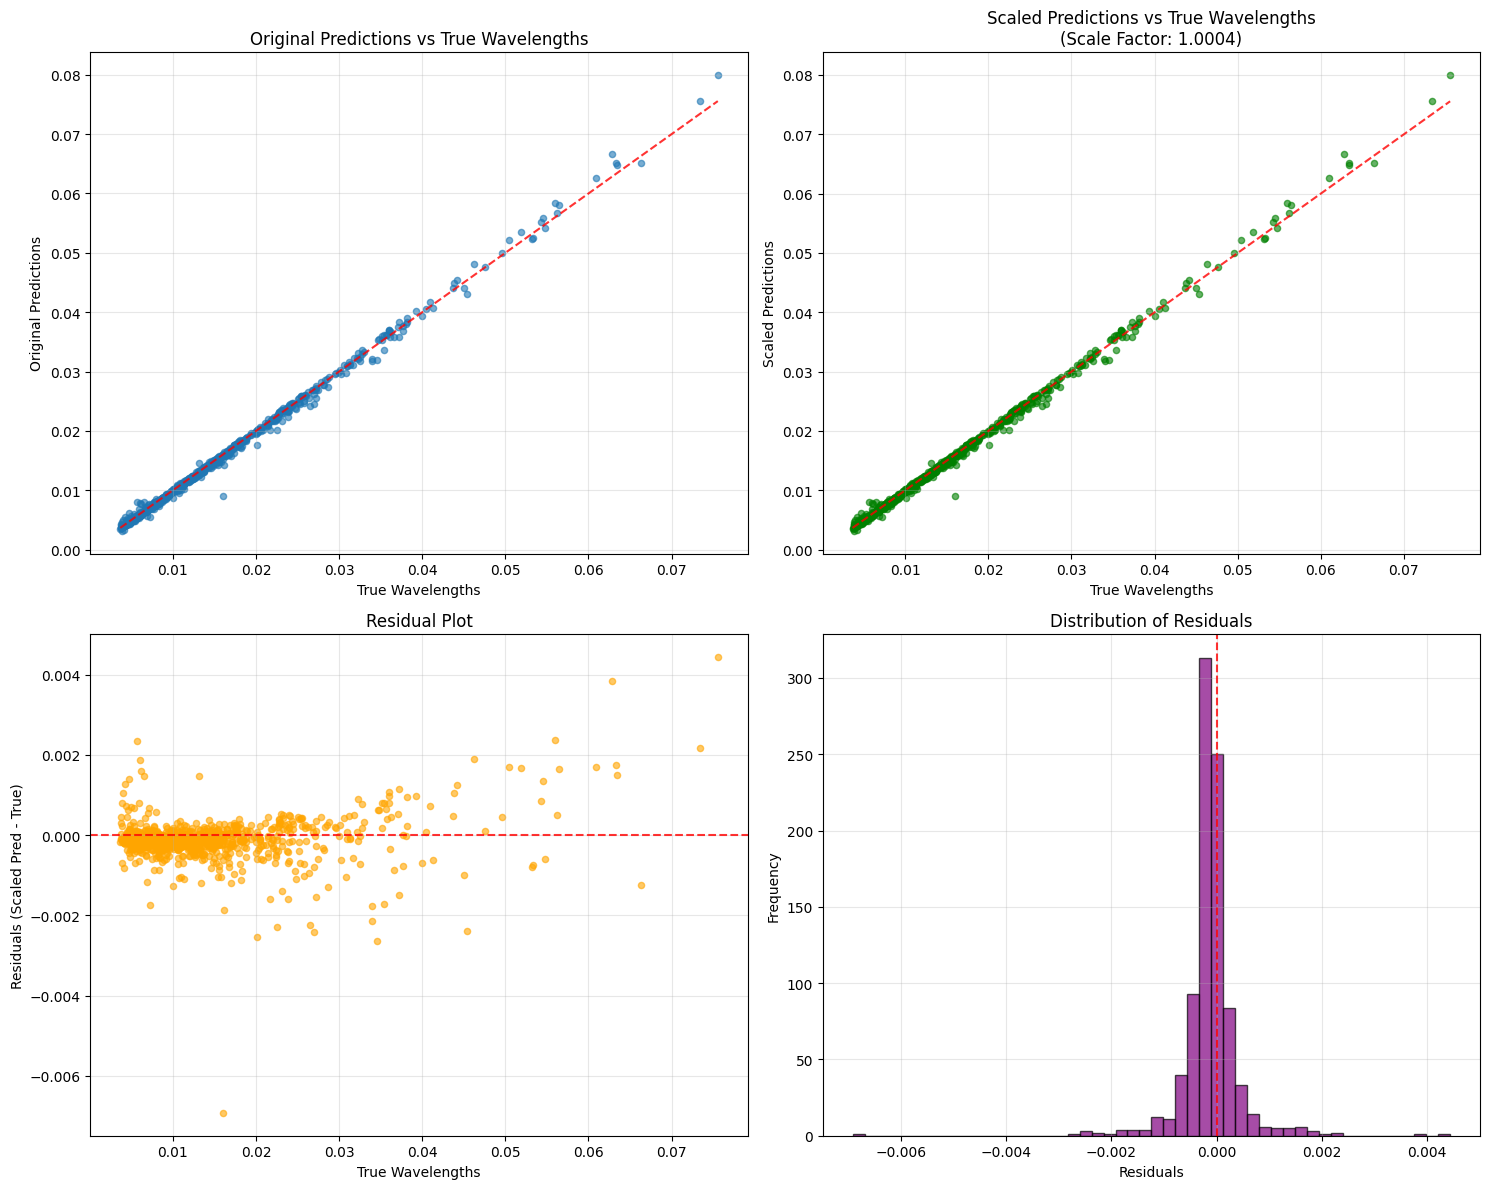


Scaled Data Analysis:
Mean Absolute Error: 0.000333
Std of Absolute Errors: 0.000478
Mean Percentage Error: 2.70%

To convert future predictions to wavelengths, use:
wavelengths = 1.000381 * predictions

Or use the convert_predictions_to_wavelength() function defined above.


In [10]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize_scalar
from sklearn.metrics import mean_squared_error, r2_score

def find_optimal_scaling(predictions, true_wavelengths, method='linear_regression'):
    """
    Find the best scaling factor to convert predictions to actual wavelengths.
    
    Parameters:
    predictions: array of predicted values
    true_wavelengths: array of actual wavelength values
    method: 'linear_regression', 'mse_optimization', or 'median_ratio'
    
    Returns:
    scaling_factor: optimal scaling factor
    scaled_predictions: predictions scaled to wavelength units
    metrics: dictionary of performance metrics
    """
    
    if method == 'linear_regression':
        # Use least squares regression: wavelength = scaling_factor * predictions
        scaling_factor = np.sum(predictions * true_wavelengths) / np.sum(predictions ** 2)
        
    elif method == 'mse_optimization':
        # Minimize MSE between scaled predictions and true wavelengths
        def mse_objective(scale):
            scaled_preds = scale * predictions
            return np.mean((scaled_preds - true_wavelengths) ** 2)
        
        result = minimize_scalar(mse_objective, bounds=(0.1, 10.0), method='bounded')
        scaling_factor = result.x
        
    elif method == 'median_ratio':
        # Use median of ratios (robust to outliers)
        ratios = true_wavelengths / (predictions + 1e-10)  # avoid division by zero
        scaling_factor = np.median(ratios[np.isfinite(ratios)])
    
    else:
        raise ValueError("Method must be 'linear_regression', 'mse_optimization', or 'median_ratio'")
    
    # Apply scaling
    scaled_predictions = scaling_factor * predictions
    
    # Calculate metrics
    mse = mean_squared_error(true_wavelengths, scaled_predictions)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(scaled_predictions - true_wavelengths))
    r2 = r2_score(true_wavelengths, scaled_predictions)
    
    metrics = {
        'scaling_factor': scaling_factor,
        'mse': mse,
        'rmse': rmse,
        'mae': mae,
        'r2_score': r2
    }
    
    return scaling_factor, scaled_predictions, metrics

# Assuming your variables are: predictions, train_avg (true values)
# Replace 'train_avg' with your actual wavelength data if different
true_wavelengths = train_avg.flatten()  # Your actual wavelength values
predictions_flat = predictions.flatten() if hasattr(predictions, 'flatten') else predictions

# Try different scaling methods
methods = ['linear_regression', 'mse_optimization', 'median_ratio']
results = {}

print("Scaling Method Comparison:")
print("=" * 60)

for method in methods:
    scale_factor, scaled_preds, metrics = find_optimal_scaling(
        predictions_flat, true_wavelengths, method=method
    )
    results[method] = (scale_factor, scaled_preds, metrics)
    
    print(f"\n{method.upper().replace('_', ' ')}:")
    print(f"  Scaling Factor: {scale_factor:.6f}")
    print(f"  RMSE: {metrics['rmse']:.6f}")
    print(f"  MAE: {metrics['mae']:.6f}")
    print(f"  R² Score: {metrics['r2_score']:.6f}")

# Choose the best method (lowest RMSE)
best_method = min(results.keys(), key=lambda x: results[x][2]['rmse'])
best_scale, best_scaled_preds, best_metrics = results[best_method]

print(f"\n{'='*60}")
print(f"BEST METHOD: {best_method.upper().replace('_', ' ')}")
print(f"Optimal Scaling Factor: {best_scale:.6f}")
print(f"{'='*60}")

# Visualization
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))

# Plot 1: Original predictions vs true values
ax1.scatter(true_wavelengths, predictions_flat, alpha=0.6, s=20)
ax1.plot([true_wavelengths.min(), true_wavelengths.max()], 
         [true_wavelengths.min(), true_wavelengths.max()], 'r--', alpha=0.8)
ax1.set_xlabel('True Wavelengths')
ax1.set_ylabel('Original Predictions')
ax1.set_title('Original Predictions vs True Wavelengths')
ax1.grid(True, alpha=0.3)

# Plot 2: Scaled predictions vs true values
ax2.scatter(true_wavelengths, best_scaled_preds, alpha=0.6, s=20, color='green')
ax2.plot([true_wavelengths.min(), true_wavelengths.max()], 
         [true_wavelengths.min(), true_wavelengths.max()], 'r--', alpha=0.8)
ax2.set_xlabel('True Wavelengths')
ax2.set_ylabel('Scaled Predictions')
ax2.set_title(f'Scaled Predictions vs True Wavelengths\n(Scale Factor: {best_scale:.4f})')
ax2.grid(True, alpha=0.3)

# Plot 3: Residuals
residuals = best_scaled_preds - true_wavelengths
ax3.scatter(true_wavelengths, residuals, alpha=0.6, s=20, color='orange')
ax3.axhline(y=0, color='r', linestyle='--', alpha=0.8)
ax3.set_xlabel('True Wavelengths')
ax3.set_ylabel('Residuals (Scaled Pred - True)')
ax3.set_title('Residual Plot')
ax3.grid(True, alpha=0.3)

# Plot 4: Error distribution
ax4.hist(residuals, bins=50, alpha=0.7, color='purple', edgecolor='black')
ax4.axvline(x=0, color='r', linestyle='--', alpha=0.8)
ax4.set_xlabel('Residuals')
ax4.set_ylabel('Frequency')
ax4.set_title('Distribution of Residuals')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Additional analysis for outliers with scaled data
scaled_absolute_errors = np.abs(best_scaled_preds - true_wavelengths)
scaled_percentage_errors = scaled_absolute_errors / (np.abs(true_wavelengths) + 1e-8)

print(f"\nScaled Data Analysis:")
print(f"Mean Absolute Error: {np.mean(scaled_absolute_errors):.6f}")
print(f"Std of Absolute Errors: {np.std(scaled_absolute_errors):.6f}")
print(f"Mean Percentage Error: {np.mean(scaled_percentage_errors)*100:.2f}%")

# Define the final scaling function
def convert_predictions_to_wavelength(predictions, scaling_factor=best_scale):
    """
    Convert model predictions to wavelength units using the optimal scaling factor.
    
    Parameters:
    predictions: array of model predictions
    scaling_factor: scaling factor (default uses the optimal value found)
    
    Returns:
    wavelengths: predictions converted to wavelength units
    """
    return scaling_factor * predictions

print(f"\nTo convert future predictions to wavelengths, use:")
print(f"wavelengths = {best_scale:.6f} * predictions")
print(f"\nOr use the convert_predictions_to_wavelength() function defined above.")

(900, 187, 283)


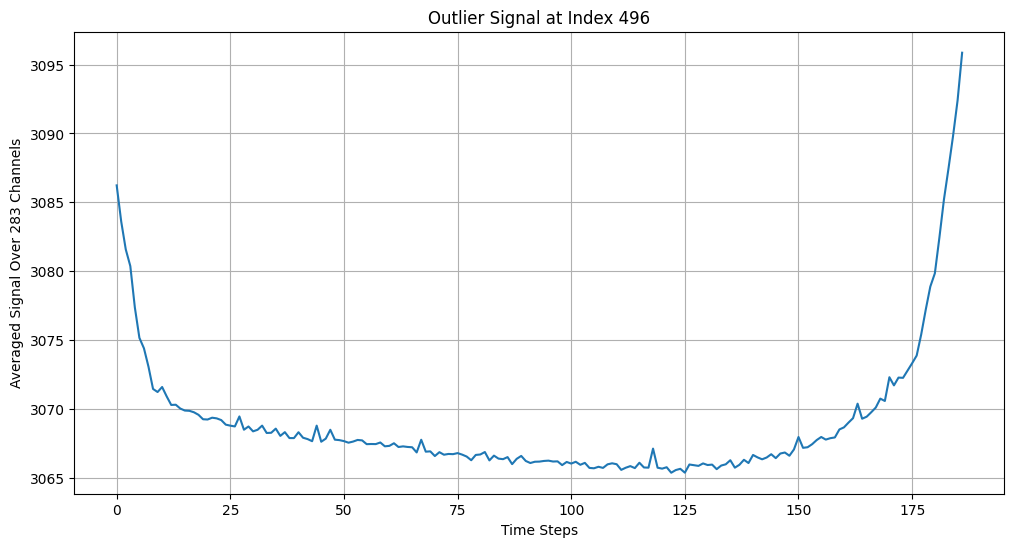

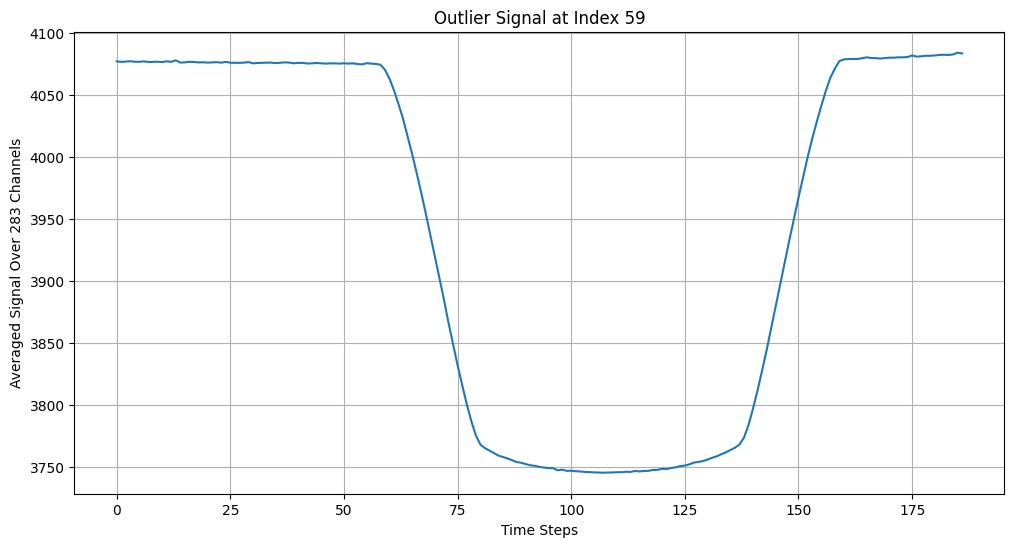

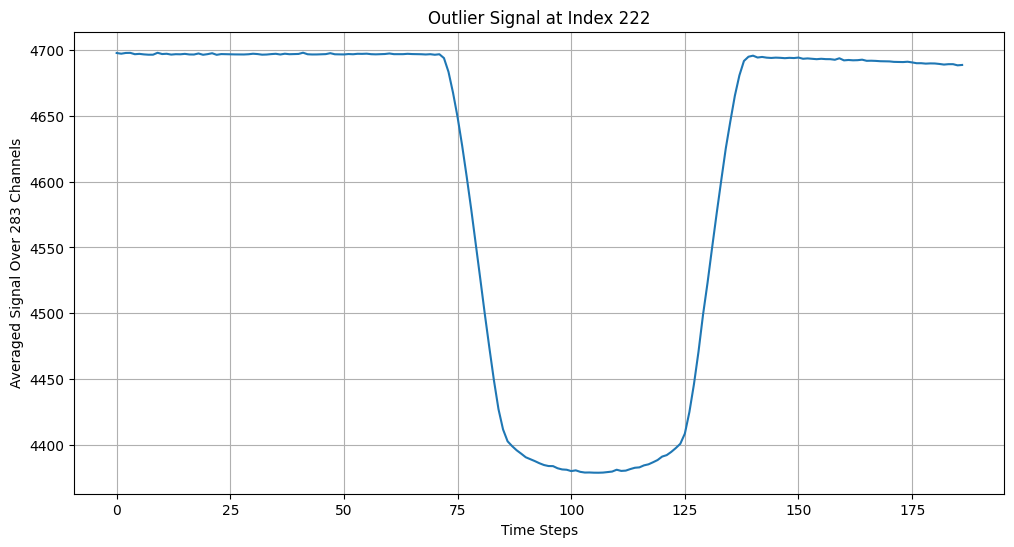

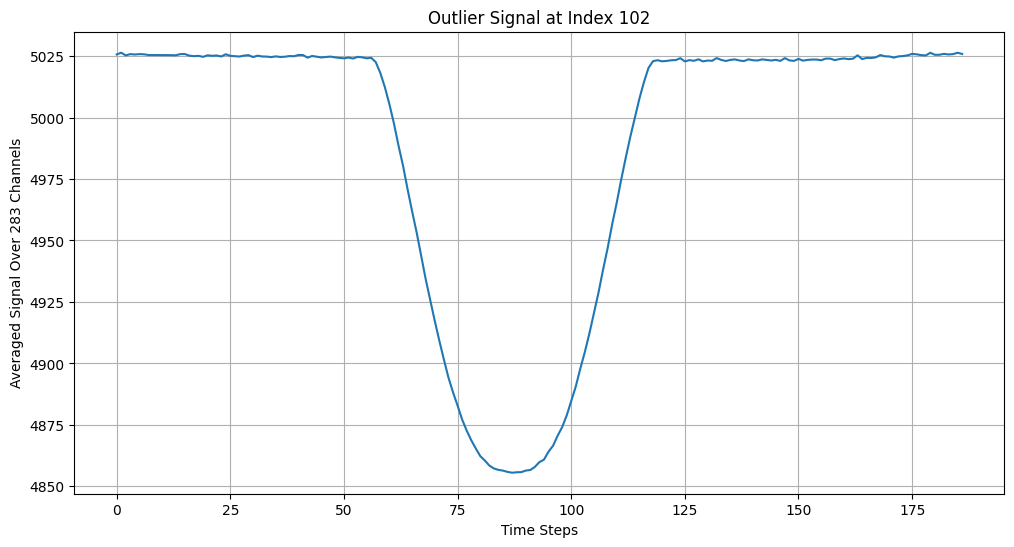

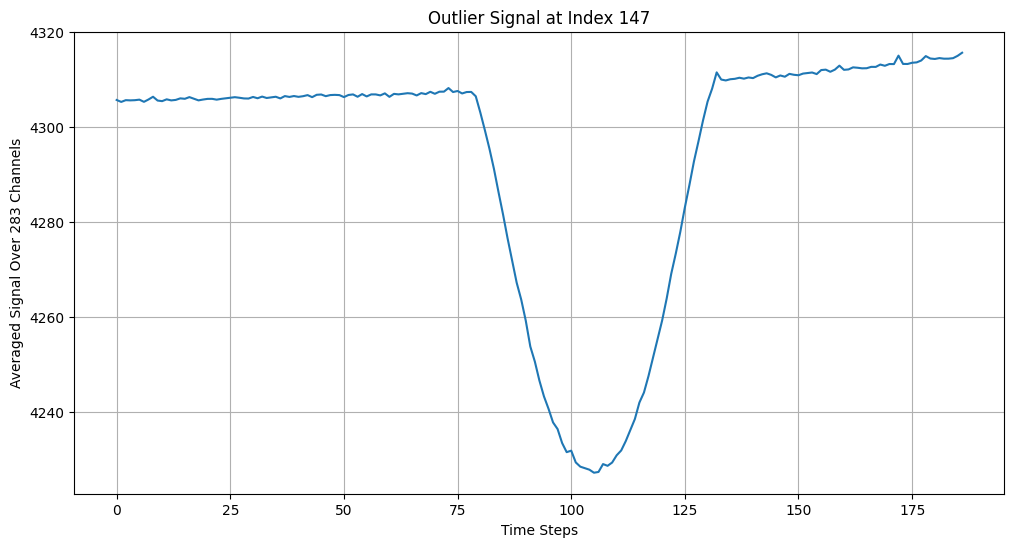

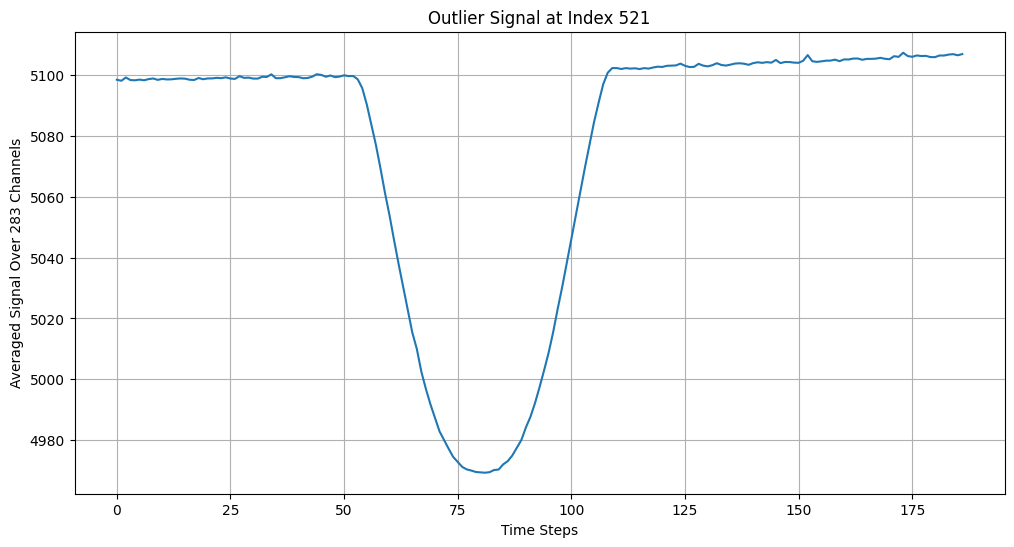

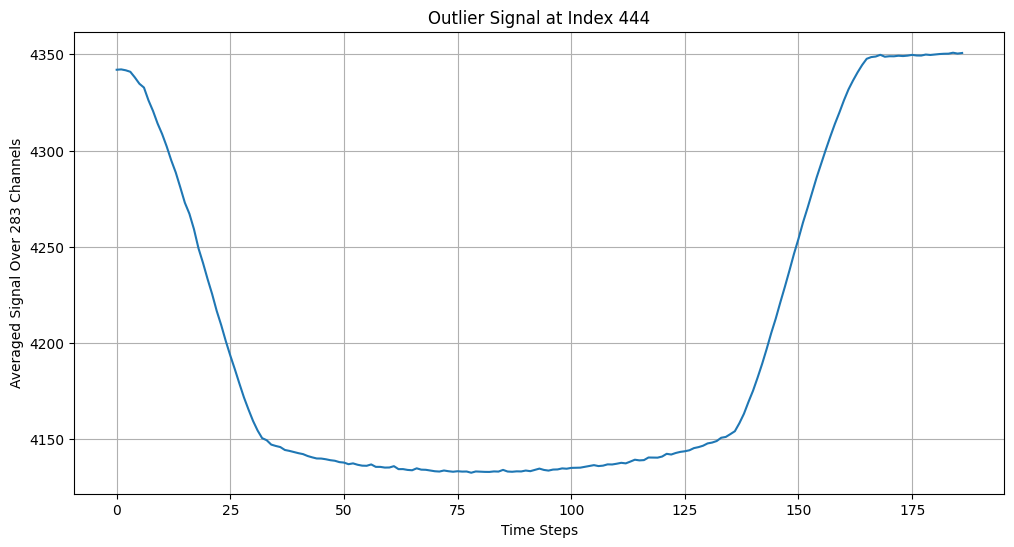

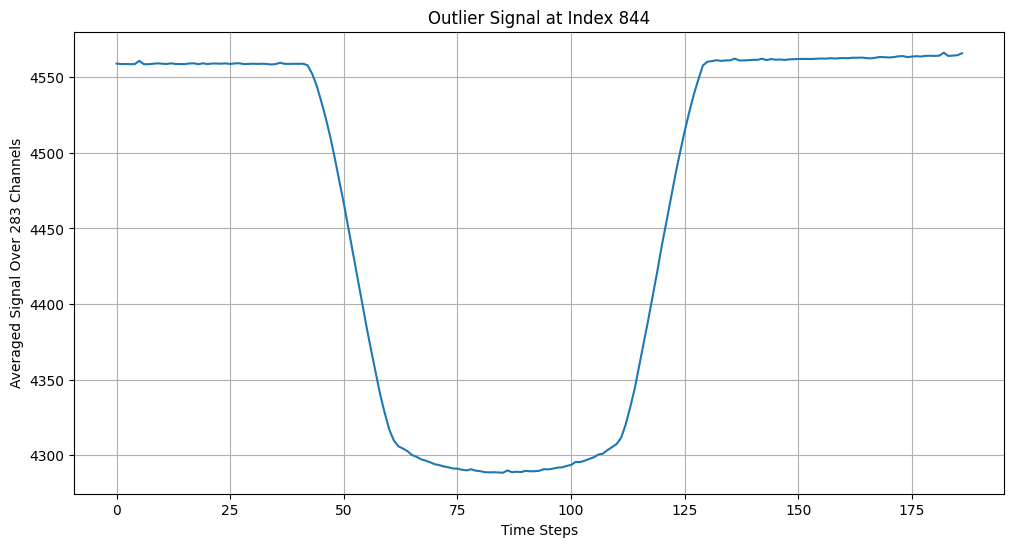

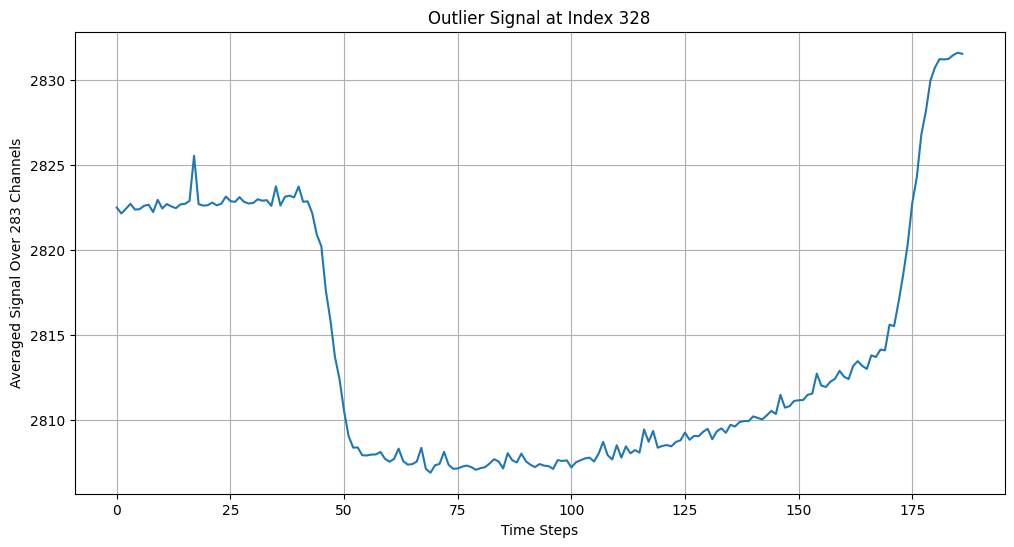

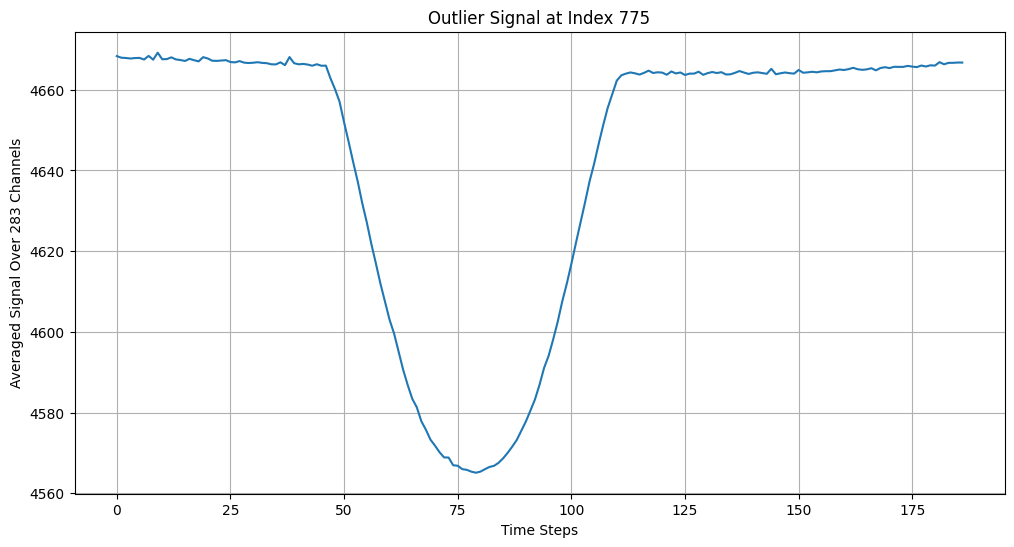

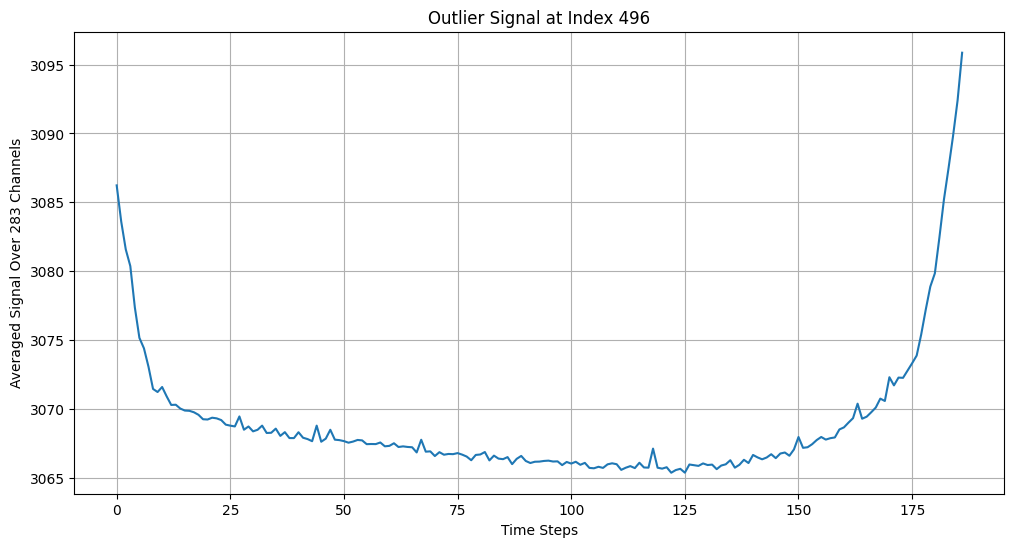

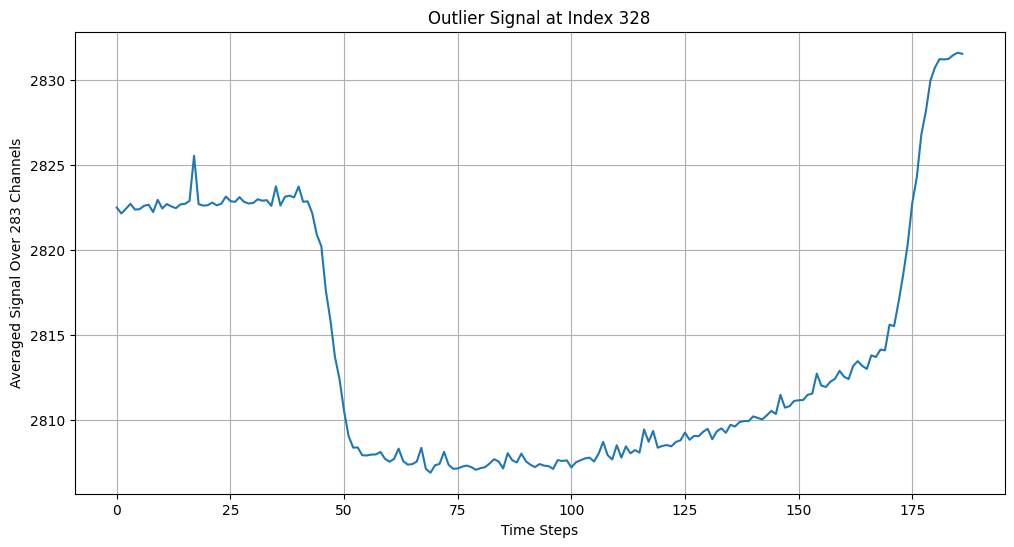

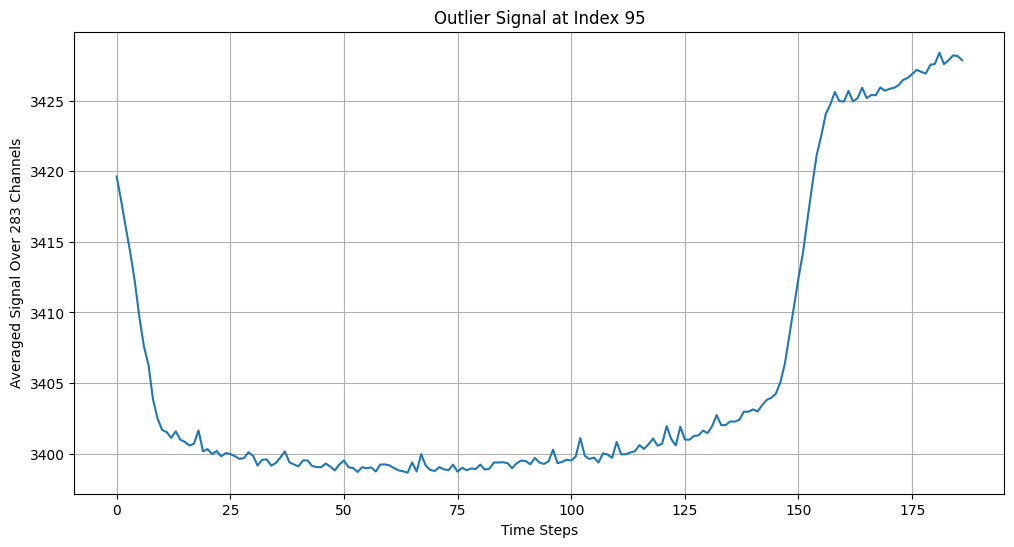

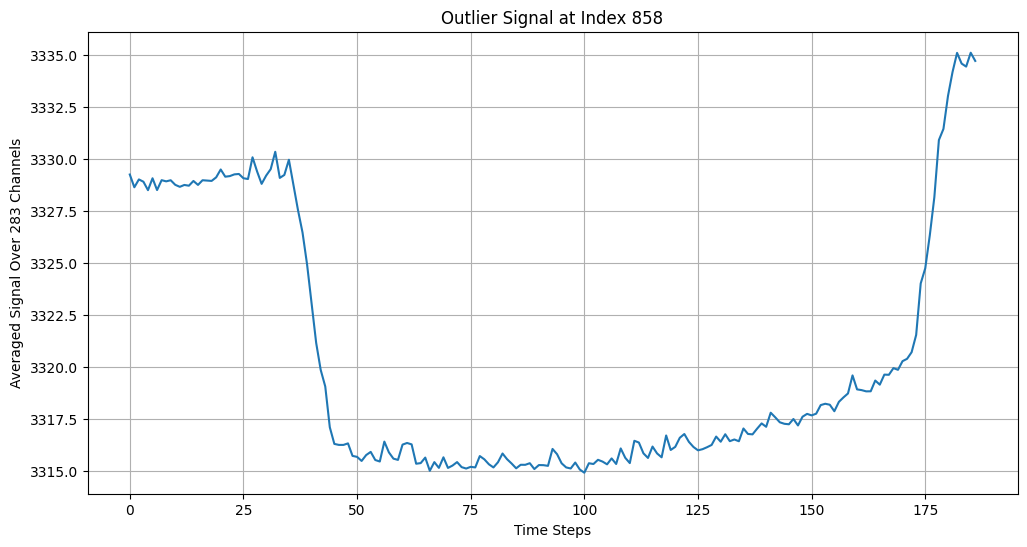

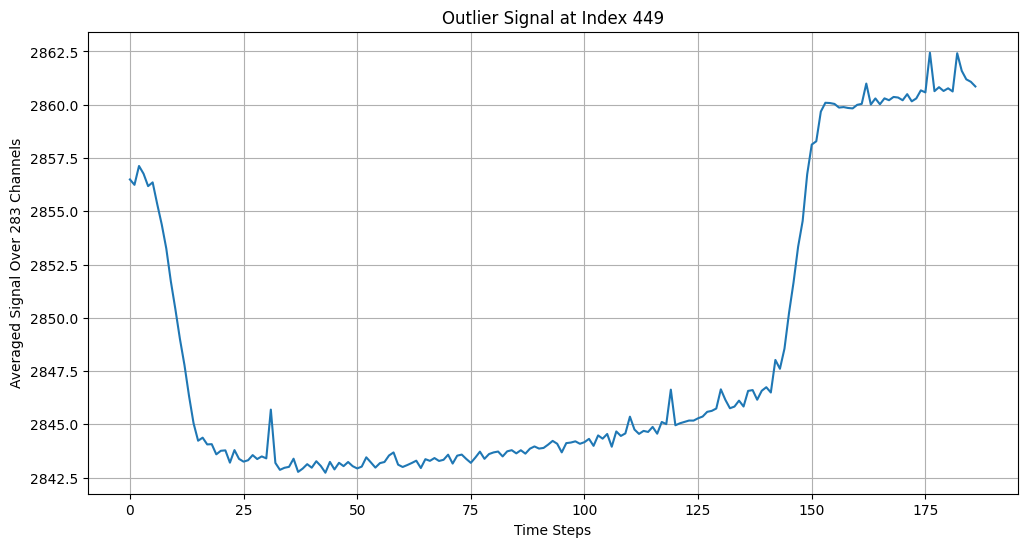

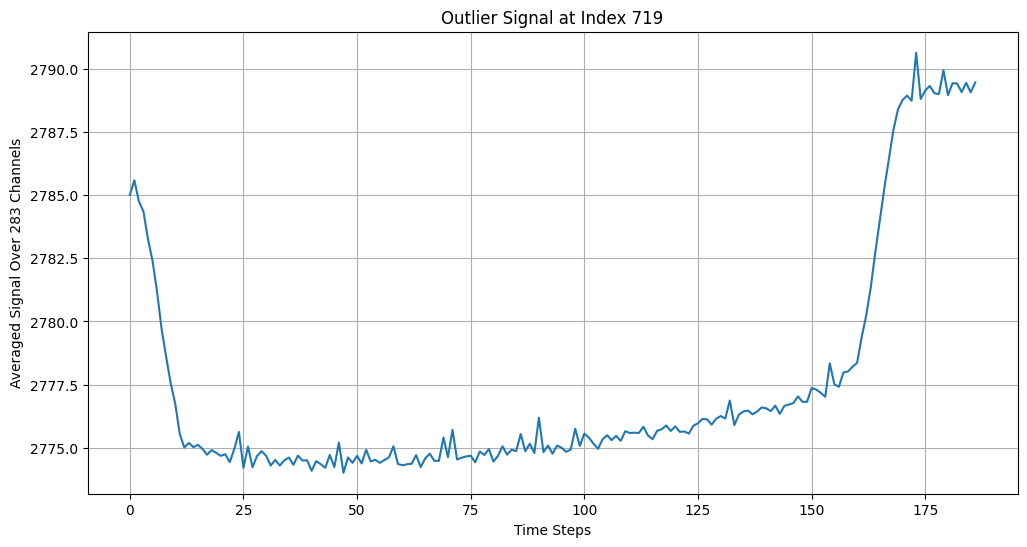

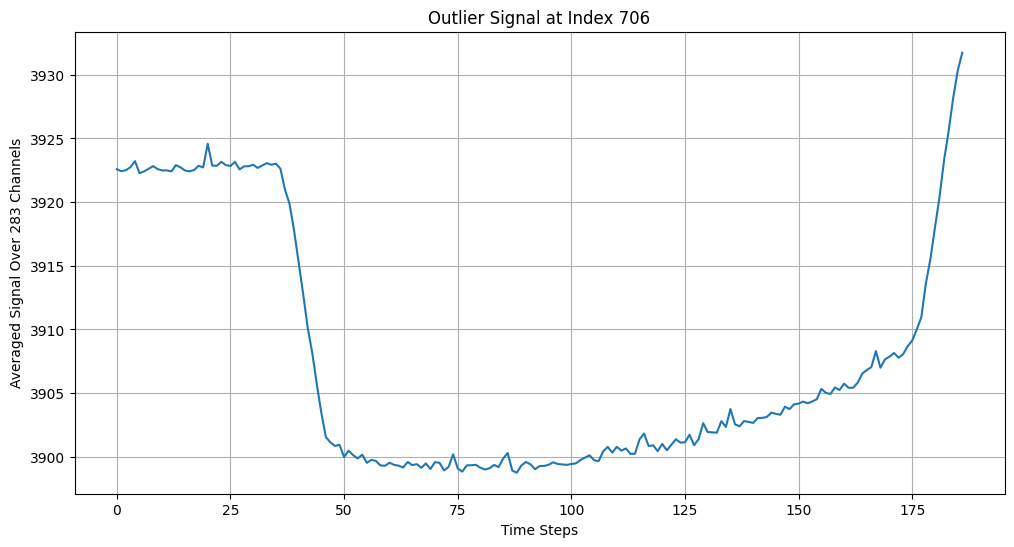

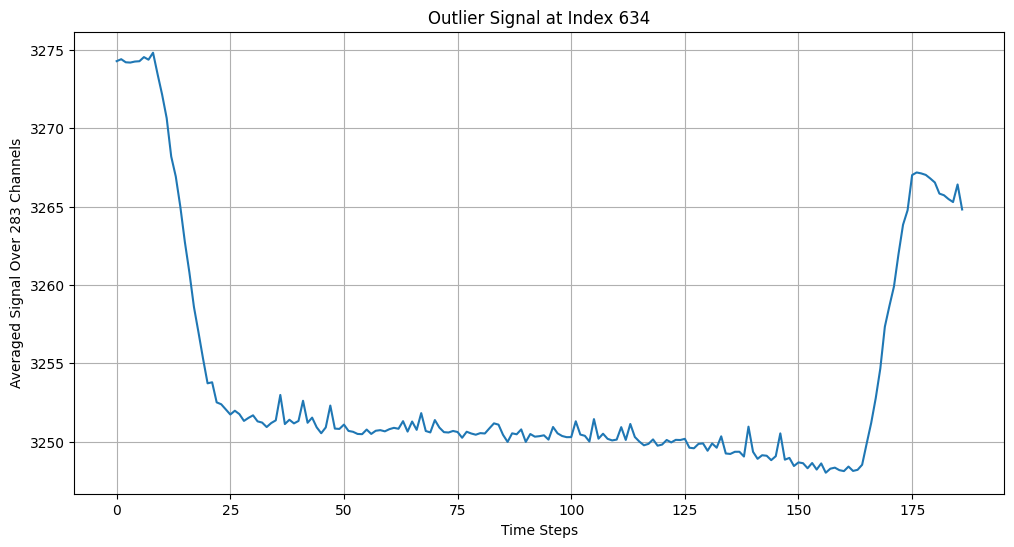

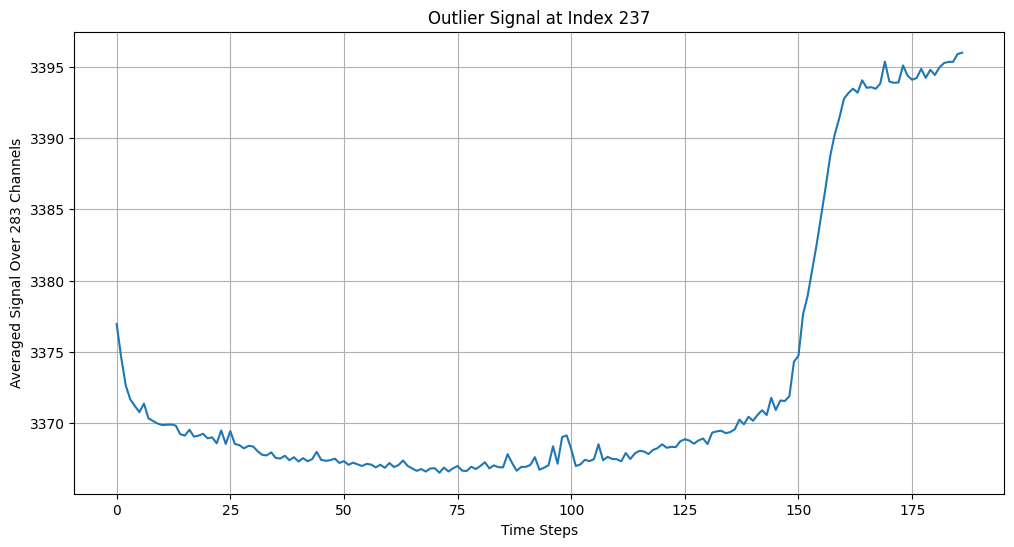

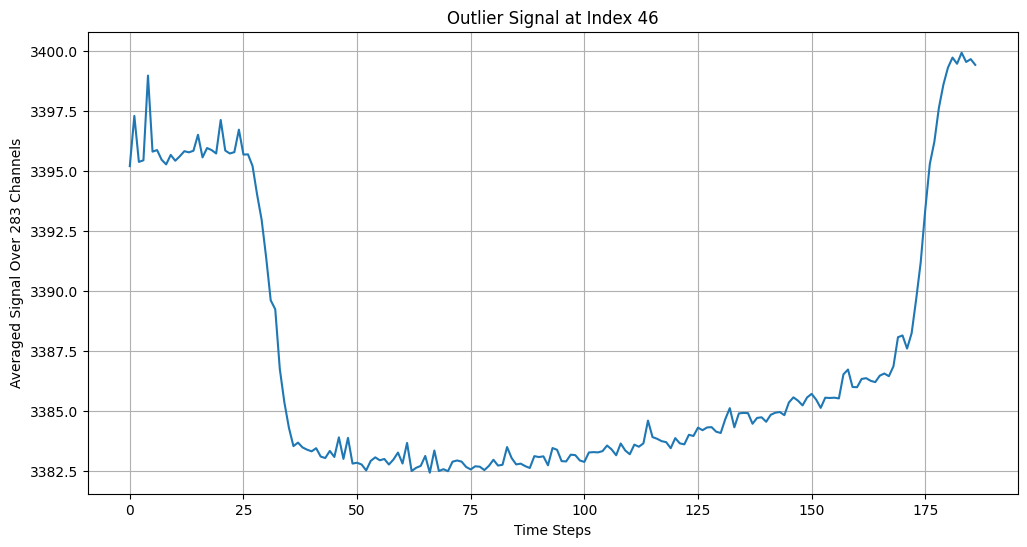

In [11]:
import matplotlib.pyplot as plt
import numpy as np

print(preprocessed_data.shape)  # Should be (900, 187, 283)


index_list = [496, 59, 222, 102, 147, 521, 444, 844, 328, 775, 496, 328, 95, 858, 449, 719, 706, 634, 237, 46]

for index in index_list:
    # Average over the 283 wavelength channels
    signal_avg = np.mean(preprocessed_data[index], axis=1)  # shape: (187,)

    # Plot the time series
    plt.figure(figsize=(12, 6))
    plt.plot(signal_avg)
    plt.title(f"Outlier Signal at Index {index}")
    plt.xlabel("Time Steps")
    plt.ylabel("Averaged Signal Over 283 Channels")
    plt.grid(True)
    plt.show()

In [ ]:
import numpy as np
from scipy.optimize import minimize
from scipy.signal import savgol_filter
from sklearn.decomposition import PCA, NMF, TruncatedSVD
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_squared_error
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

class EnhancedTransitModel:
    def __init__(self, config):
        self.cfg = config
        self.pca_model = None
        self.svd_model = None
        self.nmf_model = None
        self.scaler = StandardScaler()
        self.nmf_scaler = MinMaxScaler()  # NMF requires non-negative data
        self.is_fitted = False
        
        # Dimensionality reduction parameters
        self.n_components_pca = getattr(config, 'PCA_COMPONENTS', 10)
        self.n_components_svd = getattr(config, 'SVD_COMPONENTS', 10)
        self.n_components_nmf = getattr(config, 'NMF_COMPONENTS', 8)
        
        # Ensemble parameters
        self.ensemble_method = getattr(config, 'ENSEMBLE_METHOD', 'weighted_average')  # 'weighted_average', 'best_single', 'voting'
        self.method_weights = getattr(config, 'METHOD_WEIGHTS', {'original': 0.4, 'pca': 0.25, 'svd': 0.2, 'nmf': 0.15})
        
    def _phase_detector(self, signal):
        """Original phase detection method"""
        search_slice = self.cfg.MODEL_PHASE_DETECTION_SLICE
        min_index = np.argmin(signal[search_slice]) + search_slice.start
    
        signal1 = signal[:min_index]
        signal2 = signal[min_index:]
    
        grad1 = np.abs(np.gradient(signal1))
        phase1 = np.argmax(grad1)
    
        grad2 = np.abs(np.gradient(signal2))
        phase2 = np.argmax(grad2) + min_index
    
        return phase1, phase2
    
    def _objective_function(self, s, signal, phase1, phase2, middle):
        """Original objective function"""
        delta = self.cfg.MODEL_OPTIMIZATION_DELTA
        power = self.cfg.MODEL_POLYNOMIAL_DEGREE
        off = 7
        middle_point = (np.floor((phase2-phase1)/2)+phase1).astype(int)
        half_size = (np.floor(middle*(phase2-phase1)/2)).astype(int)
        
        begin = phase1-off
        end = phase2+off
        
        if begin < 1:
            begin = 1
        if end > 186:
            end = 186
            
        # Construct y
        y = np.concatenate([
            signal[:begin],
            signal[middle_point - half_size : middle_point + half_size] * (1 + s),
            signal[end:]
        ])
        
        x = np.arange(len(y))
        coeffs = np.polyfit(x, y, deg=power)
        poly = np.poly1d(coeffs)
        error = np.abs(poly(x) - y).mean()
        
        return error
    
    def fit_decomposition_models(self, training_signals):
        """
        Fit PCA, SVD, and NMF models on training data
        
        Parameters:
        training_signals: array of shape (n_samples, height, width) or (n_samples, n_features)
        """
        print("Fitting decomposition models...")
        print(f"Input shape: {training_signals.shape}")
        
        # Reshape signals to 2D if needed
        if len(training_signals.shape) == 3:
            n_samples, height, width = training_signals.shape
            X = training_signals.reshape(n_samples, height * width)
            print(f"Reshaped to: {X.shape}")
        else:
            X = training_signals.copy()
            print(f"Using original shape: {X.shape}")
        
        print("Fitting scalers...")
        # Fit scalers and transform data
        X_scaled = self.scaler.fit_transform(X)
        X_nmf = self.nmf_scaler.fit_transform(X)  # NMF needs non-negative data
        
        print("Fitting PCA...")
        # Fit PCA
        self.pca_model = PCA(n_components=min(self.n_components_pca, X.shape[1], X.shape[0]), random_state=42)
        self.pca_model.fit(X_scaled)
        
        print("Fitting SVD...")
        # Fit SVD
        self.svd_model = TruncatedSVD(n_components=min(self.n_components_svd, X.shape[1], X.shape[0]-1), random_state=42)
        self.svd_model.fit(X_scaled)
        
        print("Fitting NMF...")
        # Fit NMF
        self.nmf_model = NMF(n_components=min(self.n_components_nmf, X.shape[1], X.shape[0]), random_state=42, max_iter=1000)
        self.nmf_model.fit(X_nmf)
        
        self.is_fitted = True
        
        print(f"PCA explained variance ratio: {self.pca_model.explained_variance_ratio_.sum():.3f}")
        print(f"SVD explained variance ratio: {self.svd_model.explained_variance_ratio_.sum():.3f}")
        print(f"PCA components: {self.pca_model.n_components_}")
        print(f"SVD components: {self.svd_model.n_components}")
        print(f"NMF components: {self.nmf_model.n_components}")
        print("Decomposition models fitted successfully!")
    
    def _extract_features_pca(self, signal_2d):
        """Extract features using PCA"""
        if not self.is_fitted:
            raise ValueError("Models not fitted. Call fit_decomposition_models() first.")
        
        # Reshape and scale
        if len(signal_2d.shape) == 2:
            X = signal_2d.reshape(1, -1)
        else:
            X = signal_2d.reshape(1, -1)
        
        X_scaled = self.scaler.transform(X)
        
        # Transform to PCA space and back
        pca_features = self.pca_model.transform(X_scaled)
        reconstructed = self.pca_model.inverse_transform(pca_features)
        reconstructed = self.scaler.inverse_transform(reconstructed)
        
        return reconstructed.reshape(signal_2d.shape), pca_features.flatten()
    
    def _extract_features_svd(self, signal_2d):
        """Extract features using SVD"""
        if not self.is_fitted:
            raise ValueError("Models not fitted. Call fit_decomposition_models() first.")
        
        # Reshape and scale
        if len(signal_2d.shape) == 2:
            X = signal_2d.reshape(1, -1)
        else:
            X = signal_2d.reshape(1, -1)
        
        X_scaled = self.scaler.transform(X)
        
        # Transform to SVD space and back
        svd_features = self.svd_model.transform(X_scaled)
        reconstructed = self.svd_model.inverse_transform(svd_features)
        reconstructed = self.scaler.inverse_transform(reconstructed)
        
        return reconstructed.reshape(signal_2d.shape), svd_features.flatten()
    
    def _extract_features_nmf(self, signal_2d):
        """Extract features using NMF"""
        if not self.is_fitted:
            raise ValueError("Models not fitted. Call fit_decomposition_models() first.")
        
        # Reshape and scale
        if len(signal_2d.shape) == 2:
            X = signal_2d.reshape(1, -1)
        else:
            X = signal_2d.reshape(1, -1)
        
        X_nmf = self.nmf_scaler.transform(X)
        
        # Transform to NMF space and back
        nmf_features = self.nmf_model.transform(X_nmf)
        reconstructed = self.nmf_model.inverse_transform(nmf_features)
        reconstructed = self.nmf_scaler.inverse_transform(reconstructed)
        
        return reconstructed.reshape(signal_2d.shape), nmf_features.flatten()
    
    def _predict_single_method(self, signal_2d, middle, method='original'):
        """Predict using a single method"""
        try:
            if method == 'original':
                # Original method
                signal_1d = signal_2d.mean(axis=1)
                signal_1d_detection = savgol_filter(signal_1d, 31, 2)
                signal_1d = savgol_filter(signal_1d, 11, 3)
                
                phase1, phase2 = self._phase_detector(signal_1d_detection)
                
                if phase1 < 15 or phase2 > 174:
                    depth_estimate = (signal_1d.max() - signal_1d.min())/(signal_1d.max())
                    return depth_estimate, {'method': 'fallback', 'confidence': 0.3}
                
                phase1 = max(self.cfg.MODEL_OPTIMIZATION_DELTA, phase1)
                phase2 = min(len(signal_1d) - self.cfg.MODEL_OPTIMIZATION_DELTA - 1, phase2)
                
                result = minimize(
                    fun=self._objective_function,
                    x0=[0.0001],
                    args=(signal_1d, phase1, phase2, middle),
                    method="Nelder-Mead"
                )
                
                return result.x[0], {'method': 'original', 'confidence': 0.8, 'phases': (phase1, phase2)}
            
            elif method in ['pca', 'svd', 'nmf']:
                # Decomposition-based methods
                if method == 'pca':
                    reconstructed, features = self._extract_features_pca(signal_2d)
                elif method == 'svd':
                    reconstructed, features = self._extract_features_svd(signal_2d)
                elif method == 'nmf':
                    reconstructed, features = self._extract_features_nmf(signal_2d)
                
                # Use reconstructed signal for transit detection
                signal_1d = reconstructed.mean(axis=1)
                signal_1d_detection = savgol_filter(signal_1d, 31, 2)
                signal_1d = savgol_filter(signal_1d, 11, 3)
                
                # Try phase detection on reconstructed signal
                try:
                    phase1, phase2 = self._phase_detector(signal_1d_detection)
                    
                    if phase1 < 15 or phase2 > 174:
                        # Use feature-based estimation for edge cases
                        depth_estimate = self._estimate_depth_from_features(features, signal_1d)
                        return depth_estimate, {'method': f'{method}_features', 'confidence': 0.6}
                    
                    phase1 = max(self.cfg.MODEL_OPTIMIZATION_DELTA, phase1)
                    phase2 = min(len(signal_1d) - self.cfg.MODEL_OPTIMIZATION_DELTA - 1, phase2)
                    
                    result = minimize(
                        fun=self._objective_function,
                        x0=[0.0001],
                        args=(signal_1d, phase1, phase2, middle),
                        method="Nelder-Mead"
                    )
                    
                    return result.x[0], {'method': method, 'confidence': 0.7, 'phases': (phase1, phase2)}
                
                except:
                    # Fallback to feature-based estimation
                    depth_estimate = self._estimate_depth_from_features(features, signal_1d)
                    return depth_estimate, {'method': f'{method}_features', 'confidence': 0.5}
            
        except Exception as e:
            # Ultimate fallback
            signal_1d = signal_2d.mean(axis=1)
            depth_estimate = (signal_1d.max() - signal_1d.min())/(signal_1d.max())
            return depth_estimate, {'method': 'fallback', 'confidence': 0.2, 'error': str(e)}
    
    def _estimate_depth_from_features(self, features, signal_1d):
        """Estimate transit depth from decomposition features"""
        # Simple heuristic: use feature magnitudes and signal statistics
        feature_var = np.var(features)
        signal_var = np.var(signal_1d)
        signal_range = signal_1d.max() - signal_1d.min()
        
        # Combine multiple indicators
        depth_estimate = (signal_range / signal_1d.max()) * (1 + 0.1 * feature_var / (signal_var + 1e-8))
        
        # Clamp to reasonable range
        depth_estimate = np.clip(depth_estimate, 0.0001, 0.5)
        
        return depth_estimate
    
    def predict(self, single_preprocessed_signal, middle, star_features=None):
        """
        Enhanced prediction using ensemble of methods
        
        Parameters:
        single_preprocessed_signal: 2D signal array
        middle: middle parameter for optimization
        star_features: additional stellar features (to be implemented)
        """
        if not self.is_fitted:
            # Fallback to original method if decomposition models not fitted
            return self._predict_single_method(single_preprocessed_signal, middle, 'original')[0]
        
        methods = ['original', 'pca', 'svd', 'nmf']
        predictions = {}
        confidences = {}
        
        # Get predictions from all methods
        for method in methods:
            try:
                pred, info = self._predict_single_method(single_preprocessed_signal, middle, method)
                predictions[method] = pred
                confidences[method] = info['confidence']
            except Exception as e:
                # Skip failed methods
                continue
        
        if not predictions:
            # Ultimate fallback
            signal_1d = single_preprocessed_signal.mean(axis=1)
            return (signal_1d.max() - signal_1d.min())/(signal_1d.max())
        
        # Ensemble the predictions
        if self.ensemble_method == 'weighted_average':
            # Weight by confidence and predefined weights
            total_weight = 0
            weighted_sum = 0
            
            for method, pred in predictions.items():
                method_weight = self.method_weights.get(method, 0.25)
                confidence = confidences[method]
                weight = method_weight * confidence
                
                weighted_sum += weight * pred
                total_weight += weight
            
            final_prediction = weighted_sum / (total_weight + 1e-8)
            
        elif self.ensemble_method == 'best_single':
            # Use the method with highest confidence
            best_method = max(confidences.keys(), key=lambda x: confidences[x])
            final_prediction = predictions[best_method]
            
        elif self.ensemble_method == 'voting':
            # Simple median voting
            final_prediction = np.median(list(predictions.values()))
        
        return final_prediction
    
    def predict_all(self, preprocessed_signals, middle, star_features_list=None):
        """
        Predict for all signals using ensemble methods
        
        Parameters:
        preprocessed_signals: array of preprocessed signals
        middle: middle parameter
        star_features_list: list of stellar features for each signal (optional)
        """
        if star_features_list is None:
            star_features_list = [None] * len(preprocessed_signals)
        
        predictions = []
        for i, (signal, star_features) in enumerate(tqdm(zip(preprocessed_signals, star_features_list), 
                                                          desc="Predicting transits")):
            pred = self.predict(signal, middle, star_features)
            predictions.append(pred)
        
        return np.array(predictions) * self.cfg.SCALE
    
    def get_method_performances(self, test_signals, test_targets, middle):
        """
        Evaluate individual method performances for analysis
        """
        if not self.is_fitted:
            print("Models not fitted. Fitting on test data for demonstration...")
            self.fit_decomposition_models(test_signals)
        
        methods = ['original', 'pca', 'svd', 'nmf']
        performances = {}
        
        for method in methods:
            predictions = []
            for signal in tqdm(test_signals, desc=f"Testing {method}"):
                try:
                    pred, _ = self._predict_single_method(signal, middle, method)
                    predictions.append(pred * self.cfg.SCALE)
                except:
                    predictions.append(0.0)  # Failed prediction
            
            predictions = np.array(predictions)
            mse = mean_squared_error(test_targets, predictions)
            mae = np.mean(np.abs(predictions - test_targets))
            
            performances[method] = {
                'mse': mse,
                'mae': mae,
                'rmse': np.sqrt(mse),
                'predictions': predictions
            }
        
        return performances

# Usage example configuration class
class Config:
    def __init__(self):
        self.MODEL_PHASE_DETECTION_SLICE = slice(50, 150)
        self.MODEL_OPTIMIZATION_DELTA = 10
        self.MODEL_POLYNOMIAL_DEGREE = 3
        self.SCALE = 1000.0  # Your scaling factor
        
        # New parameters for enhanced model
        self.PCA_COMPONENTS = 15
        self.SVD_COMPONENTS = 12
        self.NMF_COMPONENTS = 10
        self.ENSEMBLE_METHOD = 'weighted_average'  # 'weighted_average', 'best_single', 'voting'
        self.METHOD_WEIGHTS = {
            'original': 0.35,
            'pca': 0.25, 
            'svd': 0.25,
            'nmf': 0.15
        }

# Debugging and usage example:
# Step 1: Initialize with debugging
config = Config()
model = EnhancedTransitModel(config)

# Step 2: Check your data shape
print("Data shape:", preprocessed_data.shape)
print("Target shape:", train_avg.shape)

# Step 3: Fit decomposition models
print("Fitting decomposition models...")
model.fit_decomposition_models(preprocessed_data)

# Step 4: Test single prediction first
print("Testing single prediction...")
single_pred = model.predict(preprocessed_data[0], middle=0.5)
print(f"Single prediction: {single_pred}")

# Step 5: Make all predictions
print("Making all predictions...")
predictions = model.predict_all(preprocessed_data, middle=0.5)
print(f"Predictions shape: {predictions.shape}")
print(f"First 5 predictions: {predictions[:5]}")

# Step 6: Analyze performances
print("Analyzing method performances...")
performances = model.get_method_performances(preprocessed_data, train_avg, middle=0.5)

# Step 7: Print results
for method, perf in performances.items():
    print(f"{method.upper()} - RMSE: {perf['rmse']:.6f}, MAE: {perf['mae']:.6f}")


Data shape: (900, 187, 283)
Target shape: (900,)
Fitting decomposition models...
Fitting decomposition models...
Input shape: (900, 187, 283)
Reshaped to: (900, 52921)
Fitting scalers...
Fitting PCA...
Fitting SVD...
Fitting NMF...
PCA explained variance ratio: 1.000
SVD explained variance ratio: 1.000
PCA components: 15
SVD components: 12
NMF components: 10
Decomposition models fitted successfully!
Testing single prediction...
Single prediction: 0.020126904488069367
Making all predictions...


Predicting transits: 8it [00:08,  1.10s/it]

Index 120:
  Observed Transit Depth: 0.03293
  True Transit Depth:     0.02877
  Relative Error:          14.48%


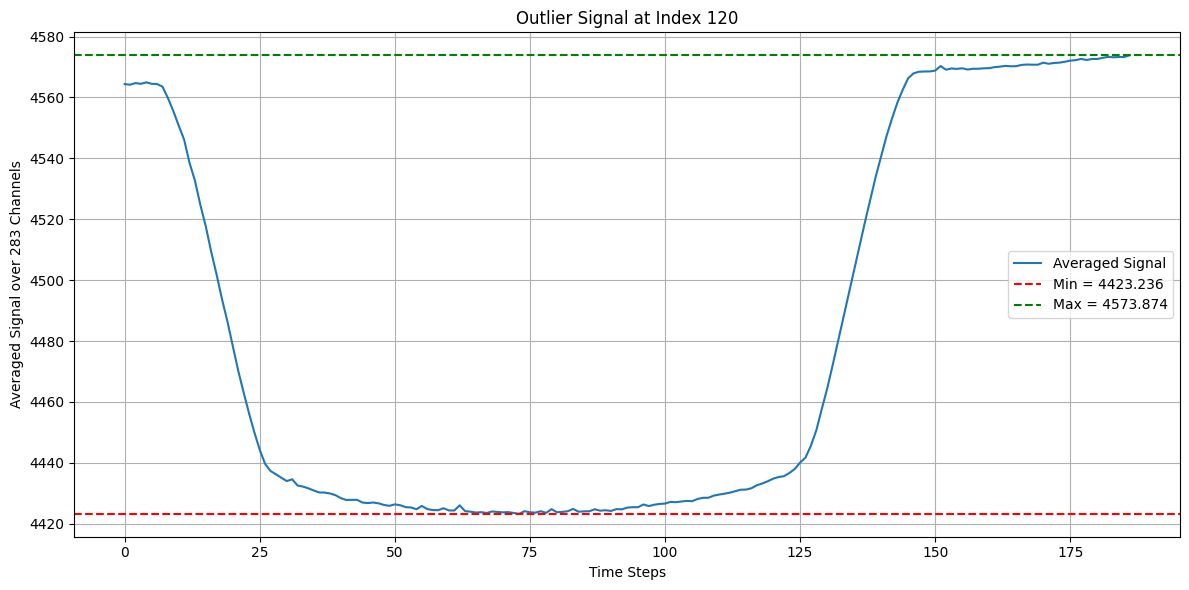

Index 496:
  Observed Transit Depth: 0.00985
  True Transit Depth:     0.01600
  Relative Error:          -38.42%


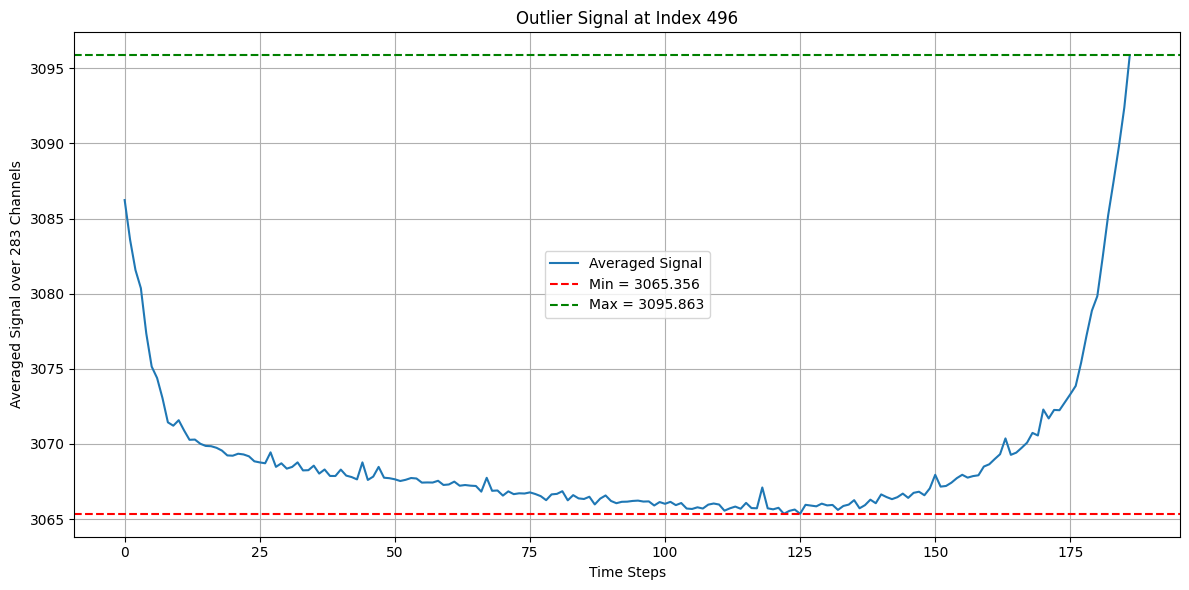

Index 210:
  Observed Transit Depth: 0.03360
  True Transit Depth:     0.03166
  Relative Error:          6.14%


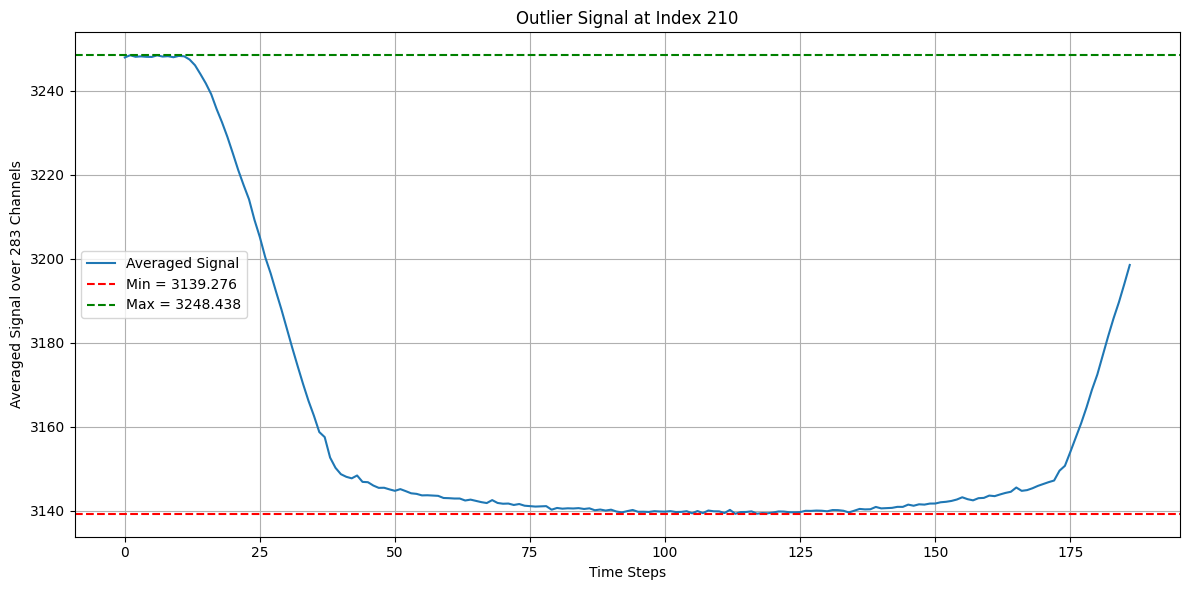

Index 42:
  Observed Transit Depth: 0.00667
  True Transit Depth:     0.00639
  Relative Error:          4.43%


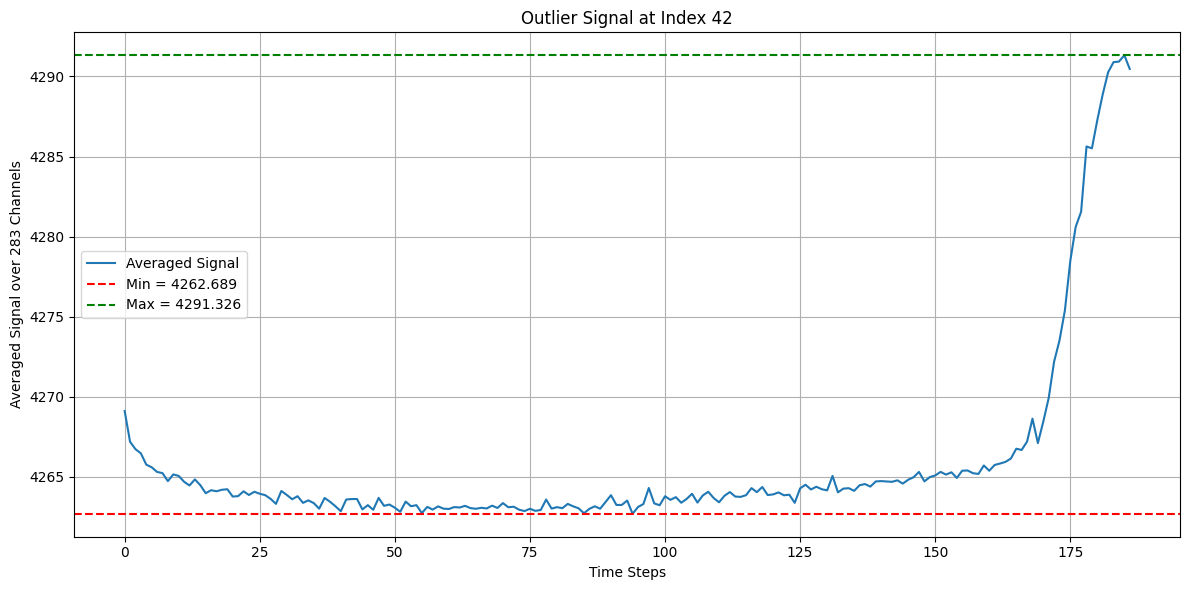

Index 289:
  Observed Transit Depth: 0.00503
  True Transit Depth:     0.00447
  Relative Error:          12.67%


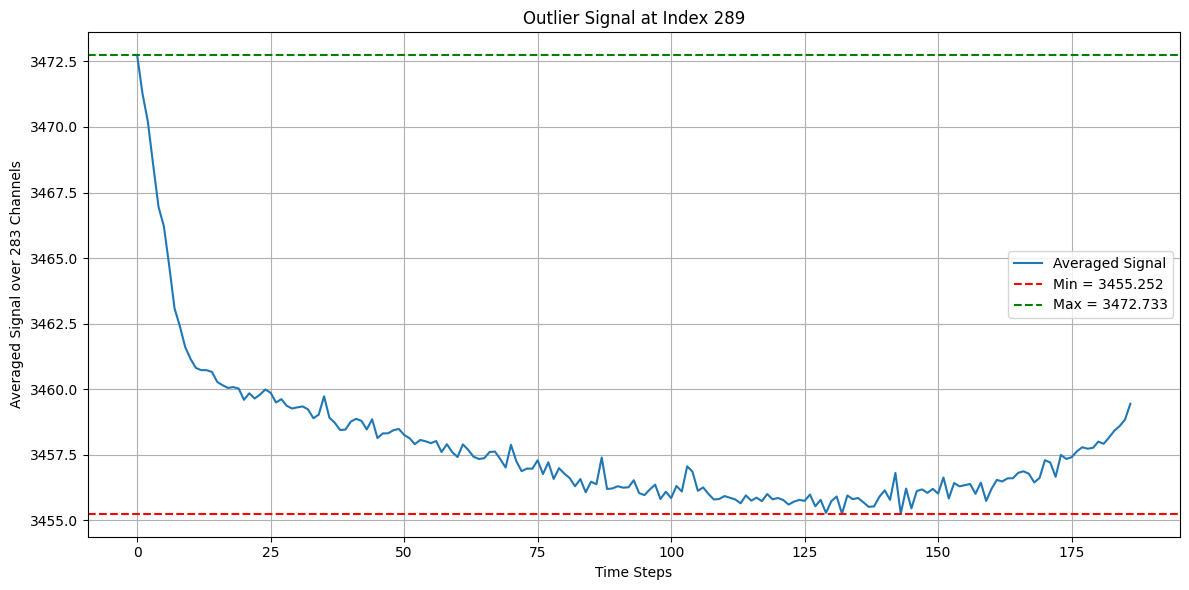

In [12]:
import matplotlib.pyplot as plt
import numpy as np


index_list = [120, 496, 210, 42, 289]

for index in index_list:
    # Step 1: Compute averaged time series
    signal_avg = np.mean(preprocessed_data[index], axis=1)  # shape: (187,)

    # Step 2: Compute observed transit depth
    min_val = np.min(signal_avg)
    max_val = np.max(signal_avg)
    observed_depth = (max_val - min_val)/max_val

    # Step 3: Retrieve actual transit depth
    if train_avg.ndim == 2:
        true_depth = np.mean(train_avg[index])
    else:
        true_depth = train_avg[index]

    # Step 4: Report and compare
    print(f"Index {index}:")
    print(f"  Observed Transit Depth: {observed_depth:.5f}")
    print(f"  True Transit Depth:     {true_depth:.5f}")
    print(f"  Relative Error:          {(observed_depth - true_depth) / (true_depth + 1e-8):.2%}")

    # Step 5: Plot
    plt.figure(figsize=(12, 6))
    plt.plot(signal_avg, label="Averaged Signal")
    plt.axhline(min_val, color='red', linestyle='--', label=f"Min = {min_val:.3f}")
    plt.axhline(max_val, color='green', linestyle='--', label=f"Max = {max_val:.3f}")
    plt.title(f"Outlier Signal at Index {index}")
    plt.xlabel("Time Steps")
    plt.ylabel("Averaged Signal over 283 Channels")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
# Print comparison
print("\n" + "="*60)
print("METHOD PERFORMANCE COMPARISON")
print("="*60)
for method, perf in performances.items():
    print(f"\n{method.upper()}:")
    print(f"  MSE (all data): {perf['mse']:.8f}")
    print(f"  MSE (no abs outliers): {perf['mse_no_abs_outliers']:.8f}")
    print(f"  MSE (no pct outliers): {perf['mse_no_pct_outliers']:.8f}")
    print(f"  RMSE: {perf['rmse']:.8f}")
    print(f"  MAE: {perf['mae']:.8f}")

# Step 3: Evaluate ensemble performance
print("\n" + "="*60)
print("ENSEMBLE MODEL PERFORMANCE")
print("="*60)
ensemble_results = model.evaluate_ensemble_performance(preprocessed_data, train_avg, middle=0.5, plot=True)